# Features and PCA

There are 1034 daily readings with gaps for each customer. A classical model is effective when the number of numbers that describe each customer is small. So this notebook

- builds 16 hand made features from the readings
- uses a log on the very skewed ones
- drops features that are highly correlated with each other
- uses PCA to look for patterns in the daily readings that we did not consider
- tests which combination of inputs is the best and saves the final 22 inputs to features.csv

All selections here are based on the training customers and no information will leak from the test set.

In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, spearmanr

from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import PredefinedSplit, cross_validate
from pipeline import get_inputs_ready

RANDOM_STATE = 42
DATA_DIR = '../data'
FIG_DIR = '../figures'
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

## 1. The cleaned data and the split are loaded.

The checks ensure that the same customers are in the same order in both files

In [2]:
# if data_cleaned.csv or split_info.csv is missing, run the cleaning notebook first
get_inputs_ready('features_pca.ipynb')

df = pd.read_csv(os.path.join(DATA_DIR, 'data_cleaned.csv'))
split_info = pd.read_csv(os.path.join(DATA_DIR, 'split_info.csv'))

assert df['CONS_NO'].is_unique, 'CONS_NO has repeats'
assert len(df) == len(split_info), 'the two files have different numbers of customers'
assert (df['CONS_NO'].values == split_info['CONS_NO'].values).all(), 'customers are in a different order'
assert (df['FLAG'].values == split_info['FLAG'].values).all(), 'labels do not match'

y = df['FLAG'].to_numpy()
is_train = (split_info['split'] == 'train').to_numpy()

print(f"Customers:          {len(df):,}")
print(f"Training customers: {is_train.sum():,}")
print(f"Test customers:     {(~is_train).sum():,}")
print(f"Theft share overall: {y.mean() * 100:.2f}%")

All inputs for features_pca.ipynb are in place.
Customers:          40,256
Training customers: 28,179
Test customers:     12,077
Theft share overall: 8.89%


## 2. Hand made features

- List all customer readings on one full calendar
- Empty days stay empty (NaN). The day 18 Sep 2016 is not considered when counting days since it has no reading for any customer

In [3]:
date_cols = []
for col in df.columns:
    if col not in ('CONS_NO', 'FLAG'):
        date_cols.append(col)

dates = pd.to_datetime(date_cols, format='%Y/%m/%d')
calendar = pd.date_range(dates.min(), dates.max(), freq='D')

# one row per customer, one column per calendar day, NaN where there is no reading
daily = np.full((len(df), len(calendar)), np.nan)
column_position = calendar.get_indexer(dates)
daily[:, column_position] = df[date_cols].to_numpy(dtype=float)

has_reading = ~np.isnan(daily)

# days that have a reading for at least one customer
# (18 Sep 2016 has no readings for anyone)
recorded_day = has_reading.any(axis=0)

print(f"Calendar days:                       {len(calendar):,}")
print(f"Days with readings in the data file: {recorded_day.sum():,}")
not_recorded = calendar[~recorded_day]
for day in not_recorded:
    print(f"Day with no readings for anyone:     {day.date()}")
print(f"Share of customer-days still empty:  {np.isnan(daily[:, recorded_day]).mean() * 100:.1f}%")

Calendar days:                       1,035
Days with readings in the data file: 1,034
Day with no readings for anyone:     2016-09-18
Share of customer-days still empty:  24.7%


**Usage level** average day, middle day and biggest day

In [4]:
features = pd.DataFrame(index=df.index)

features['mean_kwh'] = np.nanmean(daily, axis=1)
features['median_kwh'] = np.nanmedian(daily, axis=1)
features['max_kwh'] = np.nanmax(daily, axis=1)

features[['mean_kwh', 'median_kwh', 'max_kwh']].describe().round(2)

,mean_kwh,median_kwh,max_kwh
count,40256.00,40256.00,40256.00
mean,10.28,9.12,40.50
std,83.56,88.77,799.52
min,0.00,0.00,0.00
25%,2.46,1.58,8.46
50%,5.99,5.16,16.96
75%,10.47,9.30,28.15
max,13631.19,14880.00,84792.08


**Spread** is how much daily use jumps around (std_kwh). `cv_kwh` is std / mean, so it can be compared between a small flat and a big house

In [5]:
features['std_kwh'] = np.nanstd(daily, axis=1)

assert (features['mean_kwh'] > 0).all()
features['cv_kwh'] = features['std_kwh'] / features['mean_kwh']

features[['std_kwh', 'cv_kwh']].describe().round(3)

,std_kwh,cv_kwh
count,40256.000,40256.000
mean,6.107,1.222
std,53.630,2.721
min,0.000,0.004
25%,1.586,0.394
50%,3.237,0.569
75%,5.628,0.980
max,7678.419,32.140


**Zero days** percentage of days that have 0 kWh and longest run of zero days in a row. A bypassed meter may not register anything

In [6]:
def longest_run(day_mask):
    # day_mask: True/False table, one row per customer, one column per day
    n_customers, n_days = day_mask.shape
    current = np.zeros(n_customers, dtype=int)
    longest = np.zeros(n_customers, dtype=int)
    for day in range(n_days):
        current = np.where(day_mask[:, day], current + 1, 0)
        longest = np.maximum(longest, current)
    return longest


# only the days that exist in the data file, so 18 Sep 2016 doesn't break or join runs
daily_recorded = daily[:, recorded_day]
has_reading_recorded = ~np.isnan(daily_recorded)
n_readings = has_reading_recorded.sum(axis=1)

is_zero_day = (daily_recorded == 0)          # empty days compare as False here
features['zero_share'] = is_zero_day.sum(axis=1) / n_readings
features['longest_zero_run'] = longest_run(is_zero_day)

features[['zero_share', 'longest_zero_run']].describe().round(3)

,zero_share,longest_zero_run
count,40256.000,40256.000
mean,0.136,41.719
std,0.265,102.886
min,0.000,0.000
25%,0.000,0.000
50%,0.005,2.000
75%,0.097,27.000
max,0.999,1024.000


**Missing data** share of days with no reading and longest run of days without reading. The tampered meter may cease to report readings

In [7]:
n_recorded_days = daily_recorded.shape[1]
features['missing_share'] = 1 - n_readings / n_recorded_days
features['longest_missing_run'] = longest_run(~has_reading_recorded)

features[['missing_share', 'longest_missing_run']].describe().round(3)

,missing_share,longest_missing_run
count,40256.000,40256.000
mean,0.247,239.100
std,0.288,294.126
min,0.000,0.000
25%,0.006,3.000
50%,0.090,82.000
75%,0.568,458.000
max,0.995,1002.000


**Trend** The slope of a straight line through the readings (kWh per day per year) is called trend. trend_rel = slope / mean

In [8]:
time_years = np.arange(len(calendar)) / 365.25
t = np.where(has_reading, time_years, np.nan)     # time only where there is a reading

t_centered = t - np.nanmean(t, axis=1, keepdims=True)
x_centered = daily - np.nanmean(daily, axis=1, keepdims=True)

top = np.nansum(t_centered * x_centered, axis=1)
bottom = np.nansum(t_centered ** 2, axis=1)

no_spread_in_time = (bottom == 0)          # fewer than 2 readings: no line can be drawn
print(f"Customers with too few readings for a trend (set to 0): {no_spread_in_time.sum()}")

safe_bottom = np.where(no_spread_in_time, 1.0, bottom)
features['trend_slope'] = np.where(no_spread_in_time, 0.0, top / safe_bottom)
features['trend_rel'] = features['trend_slope'] / features['mean_kwh']

features[['trend_slope', 'trend_rel']].describe().round(3)

Customers with too few readings for a trend (set to 0): 0


,trend_slope,trend_rel
count,40256.000,40256.000
mean,1.408,0.022
std,39.066,1.055
min,-1857.366,-33.245
25%,-0.558,-0.173
50%,0.164,0.050
75%,1.486,0.269
max,5696.899,52.610


**Sudden drops** How many times has the monthly average dropped by half or more than half from one month to the next? How much was the largest drop? There must be at least 10 readings to count a month

In [9]:
MIN_DAYS_IN_MONTH = 10
DROP_THRESHOLD = 0.5

months = calendar.to_period('M')
month_list = months.unique()

monthly_mean = np.full((len(df), len(month_list)), np.nan)
for k in range(len(month_list)):
    in_month = (months == month_list[k])
    days_with_reading = has_reading[:, in_month].sum(axis=1)
    month_total = np.nansum(daily[:, in_month], axis=1)
    enough_days = days_with_reading >= MIN_DAYS_IN_MONTH
    monthly_mean[:, k] = np.where(enough_days, month_total / np.maximum(days_with_reading, 1), np.nan)

previous = monthly_mean[:, :-1]
current = monthly_mean[:, 1:]
usable_pair = ~np.isnan(previous) & ~np.isnan(current) & (previous > 0)

safe_previous = np.where(usable_pair, previous, 1.0)
drop = np.where(usable_pair, (previous - current) / safe_previous, np.nan)

features['n_sudden_drops'] = np.nansum(drop >= DROP_THRESHOLD, axis=1).astype(float)

biggest = np.where(usable_pair, drop, -np.inf).max(axis=1)
biggest = np.where(np.isinf(biggest), 0.0, biggest)      # no usable month pairs: no drop seen
features['max_monthly_drop'] = np.clip(biggest, 0, None)  # a rise is not a drop

no_pairs = (usable_pair.sum(axis=1) == 0)
print(f"Months in the data: {len(month_list)}")
print(f"Customers with no usable month pairs (both drop features set to 0): {no_pairs.sum()}")
features[['n_sudden_drops', 'max_monthly_drop']].describe().round(3)

Months in the data: 34
Customers with no usable month pairs (both drop features set to 0): 85


,n_sudden_drops,max_monthly_drop
count,40256.000,40256.000
mean,1.714,0.598
std,2.465,0.282
min,0.000,0.000
25%,0.000,0.369
50%,1.000,0.549
75%,2.000,0.892
max,17.000,1.000


**Weekly pattern** wweekend vs weekday use, and how different the 7 days of the week are, and how similar each day is to the same day in the following week

In [10]:
weekday = calendar.dayofweek.to_numpy()     # Monday = 0 ... Sunday = 6
is_weekend = weekday >= 5

weekend_avg = np.nanmean(daily[:, is_weekend], axis=1)
weekday_avg = np.nanmean(daily[:, ~is_weekend], axis=1)
both_avg = weekend_avg + weekday_avg
share_ok = ~np.isnan(both_avg) & (both_avg > 0)
features['weekend_share'] = np.where(share_ok, weekend_avg / np.where(share_ok, both_avg, 1.0), 0.5)
print(f"Customers where weekend_share fell back to 0.5: {(~share_ok).sum()}")

# average for each of the 7 weekdays
day_of_week_avg = np.full((len(df), 7), np.nan)
for d in range(7):
    cols = (weekday == d)
    counts = has_reading[:, cols].sum(axis=1)
    totals = np.nansum(daily[:, cols], axis=1)
    day_of_week_avg[:, d] = np.where(counts > 0, totals / np.maximum(counts, 1), np.nan)

dow_mean = np.nanmean(day_of_week_avg, axis=1)
dow_std = np.nanstd(day_of_week_avg, axis=1)
features['dow_variation'] = np.where(dow_mean > 0, dow_std / np.where(dow_mean > 0, dow_mean, 1.0), 0.0)

# correlation between each day and the same weekday one week later
today = daily[:, :-7]
week_later = daily[:, 7:]
both_present = ~np.isnan(today) & ~np.isnan(week_later)
n_pairs = both_present.sum(axis=1)

a = np.where(both_present, today, np.nan)
b = np.where(both_present, week_later, np.nan)
counts = np.maximum(n_pairs, 1)[:, None]
a_centered = a - np.nansum(a, axis=1, keepdims=True) / counts
b_centered = b - np.nansum(b, axis=1, keepdims=True) / counts
cov = np.nansum(a_centered * b_centered, axis=1)
var_a = np.nansum(a_centered ** 2, axis=1)
var_b = np.nansum(b_centered ** 2, axis=1)

corr_ok = (n_pairs >= 10) & (var_a > 0) & (var_b > 0)
features['weekly_autocorr'] = np.where(corr_ok, cov / np.sqrt(np.where(corr_ok, var_a * var_b, 1.0)), 0.0)
print(f"Customers where weekly_autocorr fell back to 0: {(~corr_ok).sum()}")

features[['weekend_share', 'dow_variation', 'weekly_autocorr']].describe().round(3)

Customers where weekend_share fell back to 0.5: 0
Customers where weekly_autocorr fell back to 0: 30


,weekend_share,dow_variation,weekly_autocorr
count,40256.000,40256.000,40256.000
mean,0.502,0.086,0.527
std,0.062,0.236,0.230
min,0.000,0.000,-0.700
25%,0.496,0.021,0.381
50%,0.504,0.034,0.550
75%,0.514,0.061,0.701
max,1.000,2.449,1.000


### How each feature looks for thieves and normal customers

Medians for every class and the Spearman correlation with `FLAG` on training customers. Each feature individually is a weak indicator of theft so the model must combine the features

In [11]:
FEATURE_GROUPS = {
    'usage level':     ['mean_kwh', 'median_kwh', 'max_kwh'],
    'spread':          ['std_kwh', 'cv_kwh'],
    'zero days':       ['zero_share', 'longest_zero_run'],
    'missing data':    ['missing_share', 'longest_missing_run'],
    'trend':           ['trend_slope', 'trend_rel'],
    'sudden drops':    ['n_sudden_drops', 'max_monthly_drop'],
    'weekly pattern':  ['weekend_share', 'dow_variation', 'weekly_autocorr'],
}
all_features = []
for group in FEATURE_GROUPS:
    for name in FEATURE_GROUPS[group]:
        all_features.append(name)
features = features[all_features]

assert not features.isna().any().any(), 'a feature has empty values'
assert np.isfinite(features.to_numpy()).all(), 'a feature has infinite values'
print(f"{len(all_features)} features for {len(features):,} customers, no empty or infinite values.\n")

train_features = features[is_train]
train_y = y[is_train]

rows = []
for group in FEATURE_GROUPS:
    for name in FEATURE_GROUPS[group]:
        rho = spearmanr(train_features[name], train_y)[0]
        rows.append({
            'group': group,
            'feature': name,
            'median normal': train_features.loc[train_y == 0, name].median(),
            'median theft': train_features.loc[train_y == 1, name].median(),
            'Spearman with FLAG': rho,
        })
class_table = pd.DataFrame(rows).set_index('feature')
class_table.round(3)

16 features for 40,256 customers, no empty or infinite values.



,group,median normal,median theft,Spearman with FLAG
feature,,,,
mean_kwh,usage level,5.809,8.602,0.135
median_kwh,usage level,5.030,6.840,0.102
max_kwh,usage level,16.289,27.398,0.177
std_kwh,spread,3.107,5.786,0.194
cv_kwh,spread,0.558,0.674,0.066
zero_share,zero days,0.005,0.003,-0.018
longest_zero_run,zero days,2.000,1.000,-0.017
missing_share,missing data,0.083,0.208,0.074
longest_missing_run,missing data,78.000,190.000,0.076


## 3. Log for very skewed features

Some features are very skewed as a few customers use thousands of kWh a day. If a feature is skewed (skew > 1 or kurtosis > 10) and it is only if the log actually makes the tails smaller that we use sign(x) * log(1 + |x|).

In [12]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))


SKEW_LIMIT = 1.0
KURT_LIMIT = 10.0

rows = []
log_features = []
for name in all_features:
    before = train_features[name].to_numpy()
    after = signed_log(before)
    skew_before = skew(before)
    kurt_before = kurtosis(before)        # excess kurtosis: 0 for a normal curve
    skew_after = skew(after)
    kurt_after = kurtosis(after)

    is_candidate = (abs(skew_before) > SKEW_LIMIT) or (kurt_before > KURT_LIMIT)
    log_helps = kurt_after < kurt_before
    if is_candidate and log_helps:
        decision = 'log'
        log_features.append(name)
    elif is_candidate:
        decision = 'keep (log makes tails worse)'
    else:
        decision = 'keep (not skewed)'

    rows.append({'feature': name, 'skew before': skew_before, 'kurtosis before': kurt_before,
                 'skew after log': skew_after, 'kurtosis after log': kurt_after, 'decision': decision})

skew_table = pd.DataFrame(rows).set_index('feature')
print(f"Log-transformed ({len(log_features)}): {log_features}\n")
skew_table.round(2)

Log-transformed (11): ['mean_kwh', 'median_kwh', 'max_kwh', 'std_kwh', 'cv_kwh', 'zero_share', 'longest_zero_run', 'trend_slope', 'trend_rel', 'n_sudden_drops', 'dow_variation']



,skew before,kurtosis before,skew after log,kurtosis after log,decision
feature,,,,,
mean_kwh,66.36,6038.54,0.13,1.00,log
median_kwh,67.48,6024.79,0.09,0.50,log
max_kwh,71.22,5332.72,-0.05,2.18,log
std_kwh,52.93,3283.65,0.76,2.99,log
cv_kwh,7.21,62.82,2.86,10.28,log
zero_share,2.10,3.17,1.90,2.25,log
longest_zero_run,3.98,19.39,0.78,-0.70,log
missing_share,0.75,-1.15,0.66,-1.27,keep (not skewed)
longest_missing_run,0.86,-0.97,-0.18,-1.55,keep (not skewed)


Before and after the log for `mean_kwh`

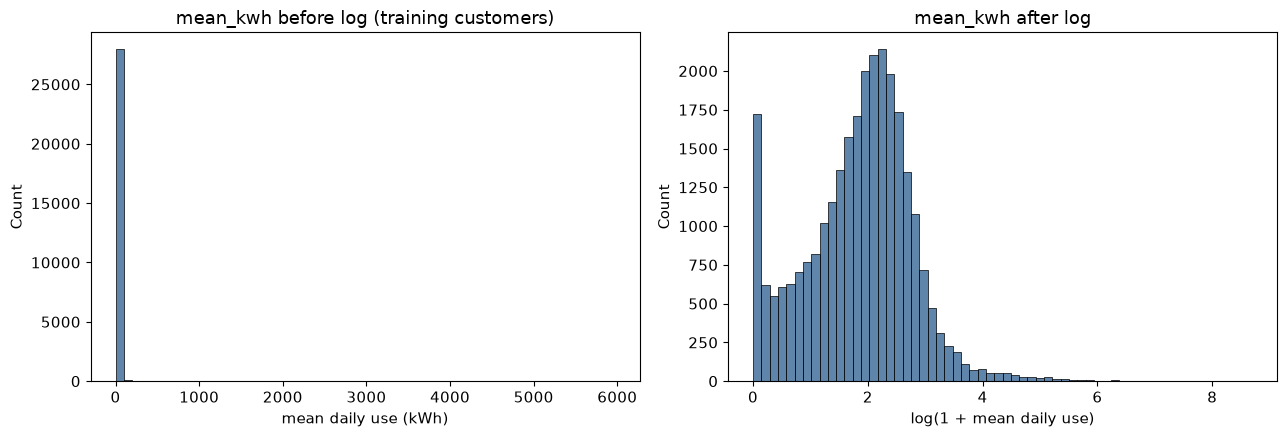

In [13]:
features_raw = features.copy()           # untransformed copy, for describing the data in the report
for name in log_features:
    features[name] = signed_log(features[name])

# before and after for the main usage feature
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(features_raw.loc[is_train, 'mean_kwh'], bins=60, ax=axes[0], color='#2b5c8f')
axes[0].set_title('mean_kwh before log (training customers)')
axes[0].set_xlabel('mean daily use (kWh)')
sns.histplot(features.loc[is_train, 'mean_kwh'], bins=60, ax=axes[1], color='#2b5c8f')
axes[1].set_title('mean_kwh after log')
axes[1].set_xlabel('log(1 + mean daily use)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step4_log_transform_mean_kwh.png'), dpi=200, bbox_inches='tight')
plt.show()

All features by class after the log (training customers, outliers hidden)


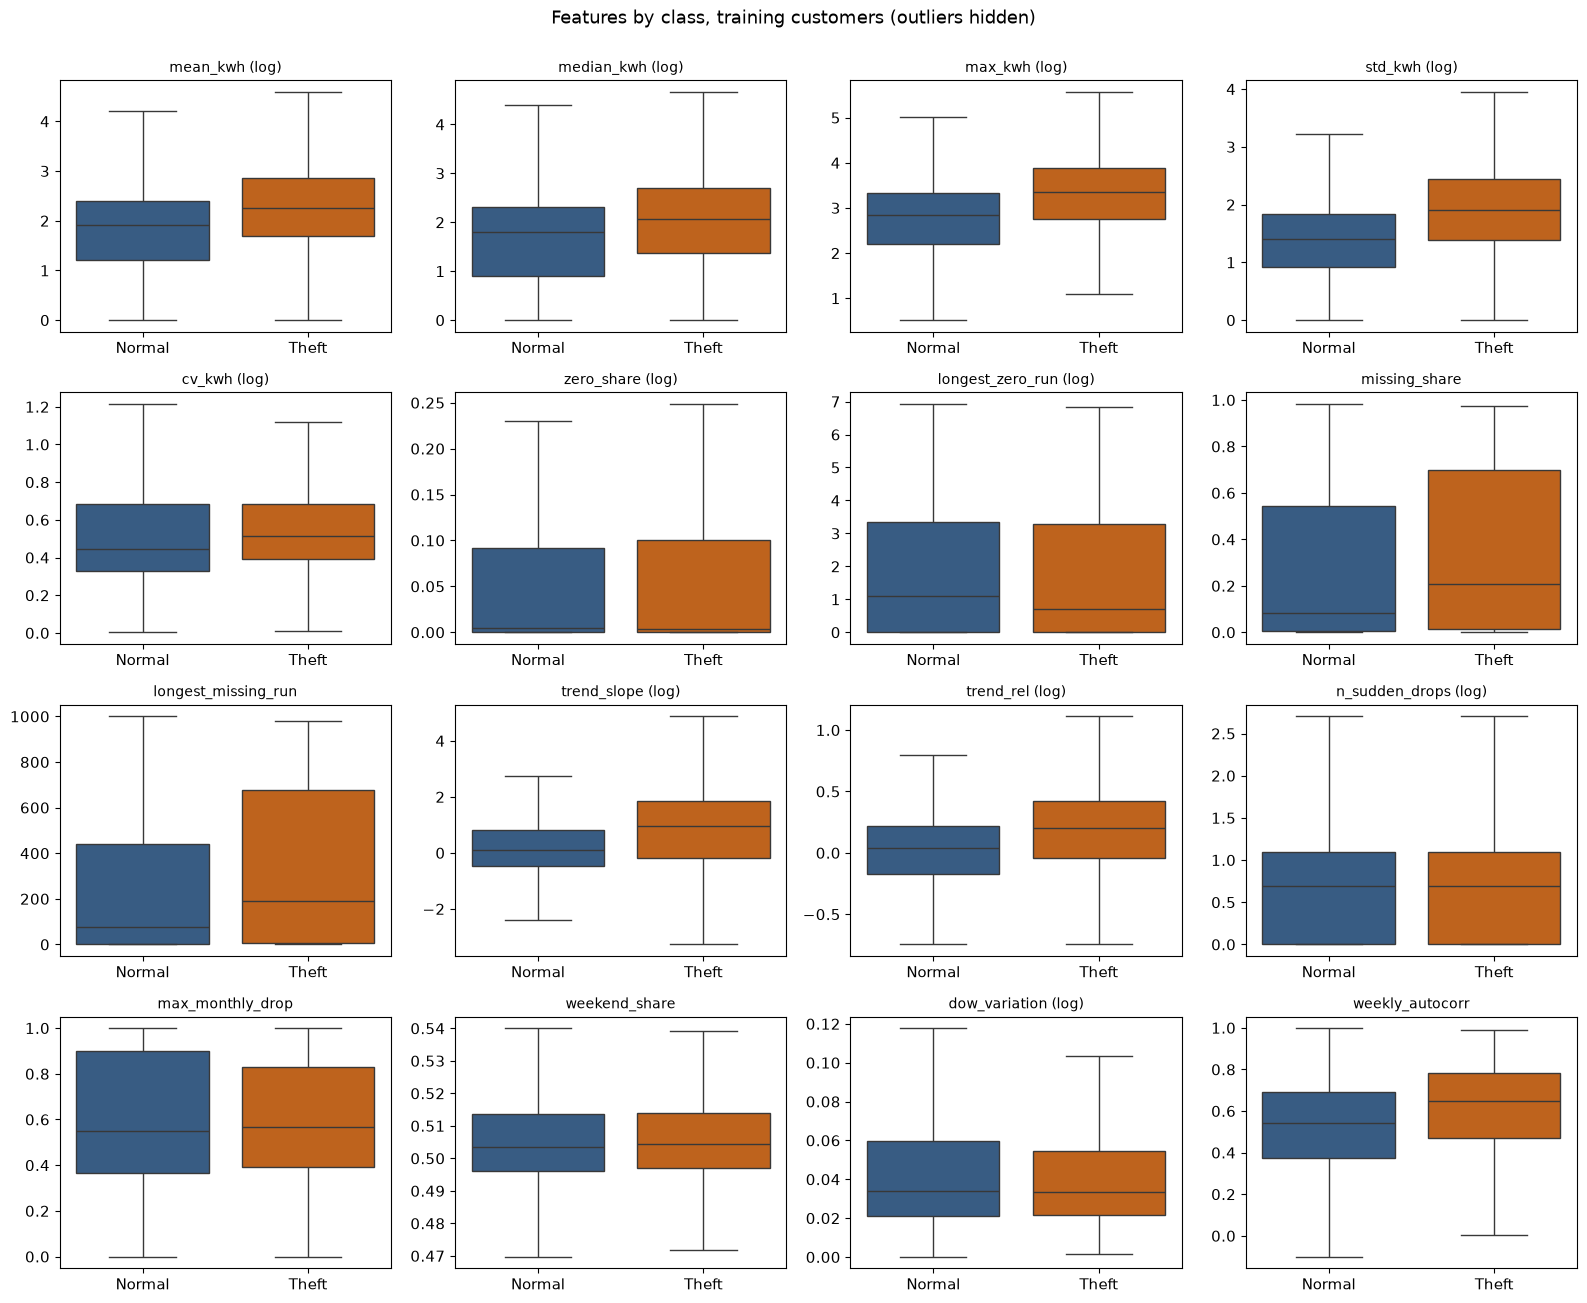

In [14]:
# distribution of every feature by class, after the log (training customers only)
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for i in range(len(all_features)):
    name = all_features[i]
    ax = axes[i // 4][i % 4]
    data = pd.DataFrame({'value': features.loc[is_train, name].to_numpy(),
                         'class': np.where(train_y == 1, 'Theft', 'Normal')})
    sns.boxplot(data=data, x='class', y='value', hue='class', ax=ax, showfliers=False,
                order=['Normal', 'Theft'], palette={'Normal': '#2b5c8f', 'Theft': '#d95f02'}, legend=False)
    title = name + ' (log)' if name in log_features else name
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.suptitle('Features by class, training customers (outliers hidden)', y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step4_features_by_class.png'), dpi=200, bbox_inches='tight')
plt.show()

## 4. Remove duplicate features

Pairs with Spearman correlation > 0.9 say virtually the same thing


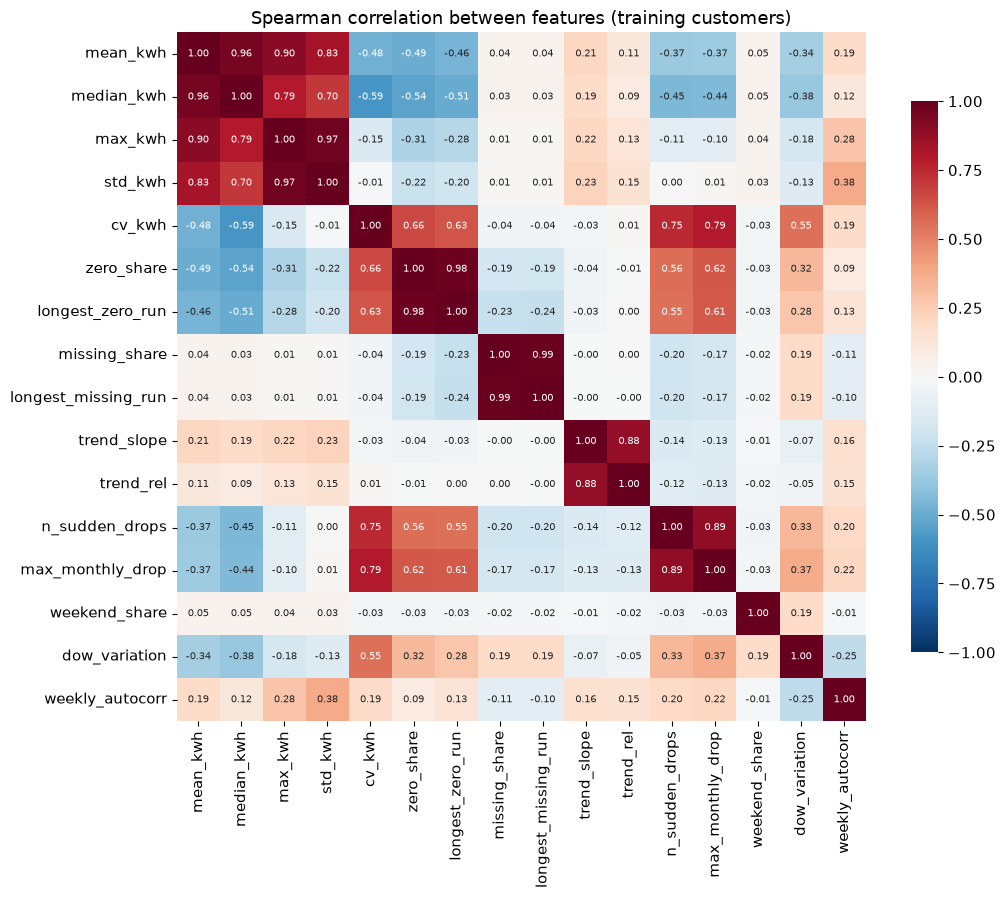

Pairs with |correlation| > 0.9:
  mean_kwh             median_kwh           0.957
  mean_kwh             max_kwh              0.902
  max_kwh              std_kwh              0.973
  zero_share           longest_zero_run     0.981
  missing_share        longest_missing_run  0.989


In [15]:
CORR_LIMIT = 0.9

corr = features[is_train].corr(method='spearman')

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            annot_kws={'size': 7}, square=True, cbar_kws={'shrink': 0.8})
plt.title('Spearman correlation between features (training customers)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step5_feature_correlation.png'), dpi=200, bbox_inches='tight')
plt.show()

flagged_pairs = []
print(f"Pairs with |correlation| > {CORR_LIMIT}:")
for i in range(len(all_features)):
    for j in range(i + 1, len(all_features)):
        value = corr.iloc[i, j]
        if abs(value) > CORR_LIMIT:
            flagged_pairs.append((all_features[i], all_features[j], value))
            print(f"  {all_features[i]:20s} {all_features[j]:20s} {value:.3f}")

For each pair we drop the extra one and score a quick random forest with 5 fold CV. If the score drops less than the normal fold to fold wobble (one fold sd) the feature adds nothing we can measure so it goes

In [16]:
MAIN_FEATURES = ['mean_kwh', 'std_kwh', 'zero_share', 'missing_share',
                 'trend_slope', 'n_sudden_drops', 'weekly_autocorr']

train_rows = split_info[is_train]
folds = PredefinedSplit(test_fold=train_rows['fold'].to_numpy())


def judge_forest():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced',
                                  n_jobs=-1, random_state=RANDOM_STATE)


def cv_scores(model, X):
    scores = cross_validate(model, X, train_y, cv=folds,
                            scoring={'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'})
    return scores['test_roc_auc'], scores['test_pr_auc']


# which feature in each flagged pair is the extra one
extras = []
for a, b, value in flagged_pairs:
    if a in MAIN_FEATURES and b not in MAIN_FEATURES:
        extra = b
    elif b in MAIN_FEATURES and a not in MAIN_FEATURES:
        extra = a
    else:
        # neither (or both) is a main feature: the one less linked to theft is the extra
        if abs(class_table.loc[a, 'Spearman with FLAG']) < abs(class_table.loc[b, 'Spearman with FLAG']):
            extra = a
        else:
            extra = b
    if extra not in extras:
        extras.append(extra)
print(f"Extras to test: {extras}\n")

base_roc, base_pr = cv_scores(judge_forest(), features.loc[is_train, all_features].to_numpy())
wobble = base_roc.std()
print(f"All 16 features: ROC-AUC {base_roc.mean():.4f} (fold sd {wobble:.4f}), PR-AUC {base_pr.mean():.4f}")
print(f"Per fold ROC-AUC: {np.round(base_roc, 4)}\n")

rows = []
to_drop = []
for extra in extras:
    keep_cols = []
    for name in all_features:
        if name != extra:
            keep_cols.append(name)
    roc, pr = cv_scores(judge_forest(), features.loc[is_train, keep_cols].to_numpy())
    loss = base_roc.mean() - roc.mean()
    if loss < wobble:
        decision = 'drop (adds nothing measurable)'
        to_drop.append(extra)
    else:
        decision = 'keep (removing it hurts)'
    rows.append({'feature removed': extra, 'ROC-AUC without it': roc.mean(),
                 'ROC-AUC lost': loss, 'PR-AUC without it': pr.mean(), 'decision': decision})

duplicate_test = pd.DataFrame(rows).set_index('feature removed')
duplicate_test.round(4)

Extras to test: ['median_kwh', 'max_kwh', 'longest_zero_run', 'longest_missing_run']

All 16 features: ROC-AUC 0.7837 (fold sd 0.0063), PR-AUC 0.3426
Per fold ROC-AUC: [0.7887 0.7749 0.7773 0.7889 0.7889]



,ROC-AUC without it,ROC-AUC lost,PR-AUC without it,decision
feature removed,,,,
median_kwh,0.7851,-0.0013,0.3436,drop (adds nothing measurable)
max_kwh,0.7839,-0.0001,0.3416,drop (adds nothing measurable)
longest_zero_run,0.7828,0.0009,0.3384,drop (adds nothing measurable)
longest_missing_run,0.7767,0.0070,0.3323,keep (removing it hurts)


The final hand made features

In [17]:
final_features = []
for name in all_features:
    if name not in to_drop:
        final_features.append(name)

final_roc, final_pr = cv_scores(judge_forest(), features.loc[is_train, final_features].to_numpy())
print(f"Dropped ({len(to_drop)}): {to_drop}")
print(f"Final hand-made features ({len(final_features)}): {final_features}\n")
print(f"All 16 features:   ROC-AUC {base_roc.mean():.4f}, PR-AUC {base_pr.mean():.4f}")
print(f"Final {len(final_features)} features:  ROC-AUC {final_roc.mean():.4f}, PR-AUC {final_pr.mean():.4f}")
print(f"Difference in ROC-AUC: {base_roc.mean() - final_roc.mean():.4f} (fold sd was {wobble:.4f})")

Dropped (3): ['median_kwh', 'max_kwh', 'longest_zero_run']
Final hand-made features (13): ['mean_kwh', 'std_kwh', 'cv_kwh', 'zero_share', 'missing_share', 'longest_missing_run', 'trend_slope', 'trend_rel', 'n_sudden_drops', 'max_monthly_drop', 'weekend_share', 'dow_variation', 'weekly_autocorr']

All 16 features:   ROC-AUC 0.7837, PR-AUC 0.3426
Final 13 features:  ROC-AUC 0.7824, PR-AUC 0.3409
Difference in ROC-AUC: 0.0013 (fold sd was 0.0063)


Each of the final features against the theft label

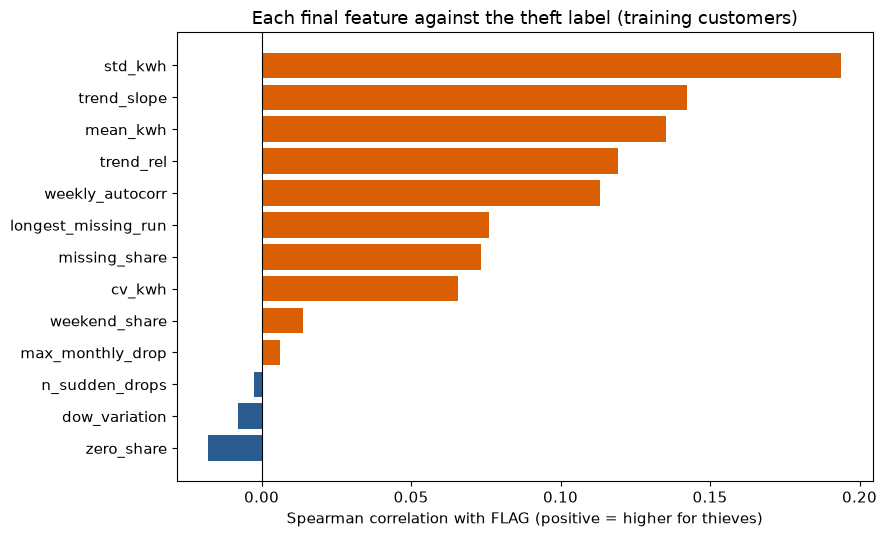

feature
zero_share            -0.018
dow_variation         -0.008
n_sudden_drops        -0.003
max_monthly_drop       0.006
weekend_share          0.014
cv_kwh                 0.066
missing_share          0.074
longest_missing_run    0.076
weekly_autocorr        0.113
trend_rel              0.119
mean_kwh               0.135
trend_slope            0.142
std_kwh                0.194
Name: Spearman with FLAG, dtype: float64

In [18]:
# how strongly each final feature goes with theft on its own (training customers)
flag_corr = class_table.loc[final_features, 'Spearman with FLAG'].sort_values()

plt.figure(figsize=(9, 5.5))
colours = []
for value in flag_corr.values:
    if value > 0:
        colours.append('#d95f02')
    else:
        colours.append('#2b5c8f')
plt.barh(flag_corr.index, flag_corr.values, color=colours)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Spearman correlation with FLAG (positive = higher for thieves)')
plt.title('Each final feature against the theft label (training customers)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step5_feature_vs_flag.png'), dpi=200, bbox_inches='tight')
plt.show()
flag_corr.round(3)

## 5. PCA on the daily readings

Steps

1. log(1 + reading) for each day, since daily use is very skewed.
2. fill empty days with the customer's own average because PCA can not take gaps
3. Standardise each day column (mean 0 sd 1)
4. fit the scaler and PCA on training customers only

In [19]:
# 1 and 2: log of each reading, then fill gaps with the customer's own average (on the log scale)
log_daily = np.log1p(daily[:, recorded_day])
own_average = np.nanmean(log_daily, axis=1, keepdims=True)
log_daily = np.where(np.isnan(log_daily), own_average, log_daily)
assert not np.isnan(log_daily).any()

# 3: scale and PCA, learned from training customers only
scaler_daily = StandardScaler().fit(log_daily[is_train])
pca_full = PCA(random_state=RANDOM_STATE).fit(scaler_daily.transform(log_daily[is_train]))

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
k90 = int(np.searchsorted(cumulative, 0.90) + 1)
k95 = int(np.searchsorted(cumulative, 0.95) + 1)

print(f"Daily columns going into PCA: {log_daily.shape[1]}")
print(f"PC1 alone explains {explained[0] * 100:.1f}% of the variance")
print(f"First 5 components: {np.round(explained[:5] * 100, 1)} %")
print(f"Components needed for 90% of the variance: {k90}")
print(f"Components needed for 95% of the variance: {k95}")

Daily columns going into PCA: 1034
PC1 alone explains 77.8% of the variance
First 5 components: [77.8  4.3  1.9  1.6  1. ] %
Components needed for 90% of the variance: 10
Components needed for 95% of the variance: 66


The amount of variance accounted for by each component

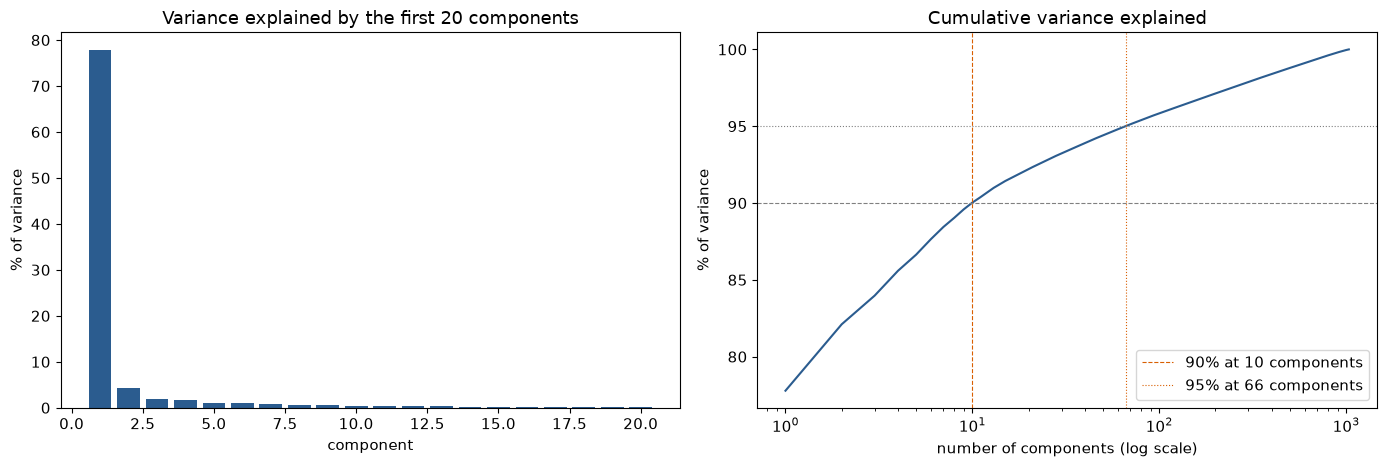

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(np.arange(1, 21), explained[:20] * 100, color='#2b5c8f')
axes[0].set_title('Variance explained by the first 20 components')
axes[0].set_xlabel('component')
axes[0].set_ylabel('% of variance')

axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative * 100, color='#2b5c8f')
axes[1].axhline(90, color='grey', linestyle='--', linewidth=0.8)
axes[1].axhline(95, color='grey', linestyle=':', linewidth=0.8)
axes[1].axvline(k90, color='#d95f02', linestyle='--', linewidth=0.8, label=f'90% at {k90} components')
axes[1].axvline(k95, color='#d95f02', linestyle=':', linewidth=0.8, label=f'95% at {k95} components')
axes[1].set_xscale('log')
axes[1].set_title('Cumulative variance explained')
axes[1].set_xlabel('number of components (log scale)')
axes[1].set_ylabel('% of variance')
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step5_pca_variance.png'), dpi=200, bbox_inches='tight')
plt.show()

The meaning of the first components. PC1 is essentially the amount of customer usage (very close to `mean_kwh`) and PC2 is primarily the trend

In [21]:
scores_train = pca_full.transform(scaler_daily.transform(log_daily[is_train]))[:, :5]

rows = []
for c in range(5):
    best_name = None
    best_rho = 0.0
    for name in final_features:
        rho = spearmanr(scores_train[:, c], features.loc[is_train, name])[0]
        if abs(rho) > abs(best_rho):
            best_rho = rho
            best_name = name
    rows.append({'component': f'PC{c + 1}', '% variance': explained[c] * 100,
                 'closest feature': best_name, 'Spearman': best_rho})
pd.DataFrame(rows).set_index('component').round(3)

,% variance,closest feature,Spearman
component,,,
PC1,77.782,mean_kwh,0.974
PC2,4.326,trend_slope,0.727
PC3,1.863,trend_slope,0.262
PC4,1.617,zero_share,-0.262
PC5,1.049,trend_rel,-0.168


The first two components for 6,000 random training customers. Thieves are intermingled with regular customers

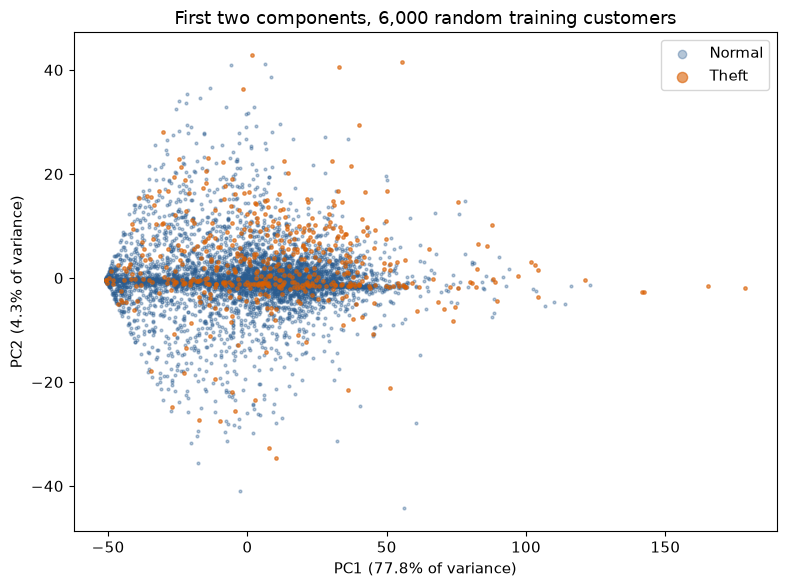

In [22]:
rng = np.random.default_rng(RANDOM_STATE)
train_positions = np.flatnonzero(is_train)
sample = rng.choice(len(train_positions), size=6000, replace=False)
plot_scores = scores_train[sample]
plot_y = train_y[sample]

plt.figure(figsize=(8, 6))
plt.scatter(plot_scores[plot_y == 0, 0], plot_scores[plot_y == 0, 1], s=4, alpha=0.35,
            color='#2b5c8f', label='Normal')
plt.scatter(plot_scores[plot_y == 1, 0], plot_scores[plot_y == 1, 1], s=6, alpha=0.6,
            color='#d95f02', label='Theft')
plt.xlabel(f'PC1 ({explained[0] * 100:.1f}% of variance)')
plt.ylabel(f'PC2 ({explained[1] * 100:.1f}% of variance)')
plt.title('First two components, 6,000 random training customers')
plt.legend(markerscale=3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step5_pca_scatter.png'), dpi=200, bbox_inches='tight')
plt.show()

## 6. Which inputs to use

On the same 5 folds, 6 input sets were compared using 2 quick judge models (logistic regression and random forest). These judges are only used to select the inputs. They are not the final models

In [23]:
X_daily_train = log_daily[is_train]
n_daily = X_daily_train.shape[1]


def drop_first_component(scores):
    return scores[:, 1:]


def build(feature_names, k, drop_pc1):
    # returns the input table and the preparation step for one input set
    parts = []
    branches = []
    start = 0
    if len(feature_names) > 0:
        parts.append(features.loc[is_train, feature_names].to_numpy())
        branches.append(('features', StandardScaler(), list(range(0, len(feature_names)))))
        start = len(feature_names)
    if k is not None:
        parts.append(X_daily_train)
        pca_steps = [('scale', StandardScaler()),
                     ('pca', PCA(n_components=k, random_state=RANDOM_STATE))]
        if drop_pc1:
            pca_steps.append(('drop_pc1', FunctionTransformer(drop_first_component)))
        pca_steps.append(('rescale', StandardScaler()))
        branches.append(('pca', Pipeline(pca_steps), list(range(start, start + n_daily))))
    return np.hstack(parts), ColumnTransformer(branches)


def make_model(kind):
    if kind == 'Logistic regression':
        return LogisticRegression(class_weight='balanced', max_iter=3000)
    return judge_forest()


n_final = len(final_features)
input_sets = {
    'All 16 features':                       (all_features, None, False),
    f'Final features ({n_final})':           (final_features, None, False),
    f'PCA 90% ({k90} components)':           ([], k90, False),
    f'PCA 95% ({k95} components)':           ([], k95, False),
    'Final features + PCA 90%':              (final_features, k90, False),
    'Final features + PCA 90% without PC1':  (final_features, k90, True),
}

Run all six input sets

In [24]:
results = []
fold_scores = {}
for set_name in input_sets:
    feature_names, k, drop_pc1 = input_sets[set_name]
    n_inputs = len(feature_names)
    if k is not None:
        n_inputs = n_inputs + k
        if drop_pc1:
            n_inputs = n_inputs - 1
    for kind in ['Logistic regression', 'Random forest']:
        X, prepare = build(feature_names, k, drop_pc1)
        model = Pipeline([('prepare', prepare), ('model', make_model(kind))])
        roc, pr = cv_scores(model, X)
        fold_scores[(set_name, kind)] = roc
        results.append({'inputs': set_name, 'n inputs': n_inputs, 'model': kind,
                        'ROC-AUC mean': roc.mean(), 'ROC-AUC sd': roc.std(),
                        'PR-AUC mean': pr.mean(), 'PR-AUC sd': pr.std()})
    print(f"done: {set_name}")

results = pd.DataFrame(results)
results.round(3)

done: All 16 features
done: Final features (13)
done: PCA 90% (10 components)
done: PCA 95% (66 components)
done: Final features + PCA 90%
done: Final features + PCA 90% without PC1


,inputs,n inputs,model,ROC-AUC mean,ROC-AUC sd,PR-AUC mean,PR-AUC sd
0,All 16 features,16,Logistic regression,0.740,0.004,0.249,0.011
1,All 16 features,16,Random forest,0.784,0.006,0.342,0.027
2,Final features (13),13,Logistic regression,0.738,0.005,0.242,0.011
3,Final features (13),13,Random forest,0.782,0.006,0.341,0.024
4,PCA 90% (10 components),10,Logistic regression,0.670,0.011,0.216,0.015
5,PCA 90% (10 components),10,Random forest,0.758,0.009,0.304,0.018
6,PCA 95% (66 components),66,Logistic regression,0.688,0.005,0.252,0.012
7,PCA 95% (66 components),66,Random forest,0.778,0.003,0.365,0.010
8,Final features + PCA 90%,23,Logistic regression,0.749,0.006,0.256,0.015
9,Final features + PCA 90%,23,Random forest,0.799,0.003,0.376,0.021


The results as a chart

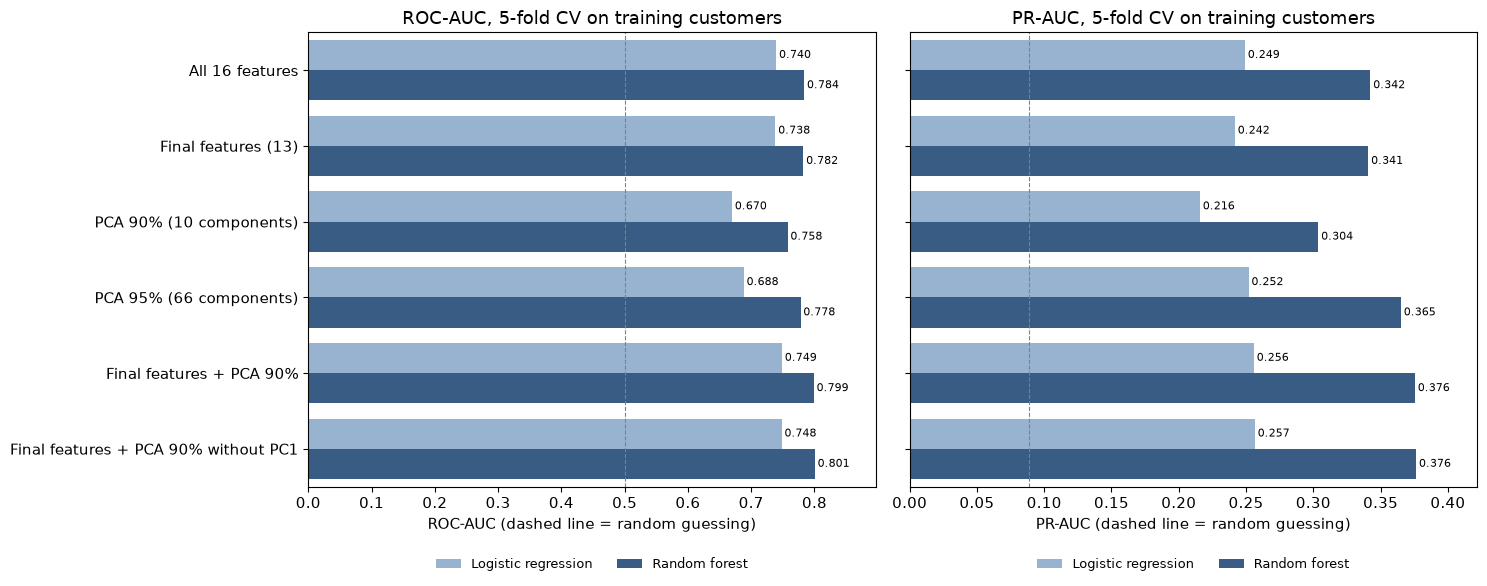

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metric, baseline in [(axes[0], 'ROC-AUC', 0.5), (axes[1], 'PR-AUC', train_y.mean())]:
    sns.barplot(data=results, y='inputs', x=f'{metric} mean', hue='model', ax=ax,
                palette=['#8fb3d9', '#2b5c8f'], orient='h')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
    ax.axvline(baseline, color='grey', linestyle='--', linewidth=0.8)
    ax.set_title(f'{metric}, 5-fold CV on training customers')
    ax.set_xlabel(f'{metric} (dashed line = random guessing)')
    ax.set_ylabel('')
    ax.set_xlim(0, results[f'{metric} mean'].max() * 1.12)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=9, frameon=False)
axes[1].set_yticklabels([])
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step5_pca_vs_features.png'), dpi=200, bbox_inches='tight')
plt.show()

Does the winner win on average or does the winner beat the plain 13 features in all folds?

In [26]:
# does the winner beat the plain final features in every fold, or only on average?
chosen_set = 'Final features + PCA 90% without PC1'
compare_with = f'Final features ({n_final})'
for kind in ['Logistic regression', 'Random forest']:
    gain = fold_scores[(chosen_set, kind)] - fold_scores[(compare_with, kind)]
    print(f"{kind:20s} ROC-AUC gain per fold: {np.round(gain, 4)}  (better in {(gain > 0).sum()} of 5 folds)")

Logistic regression  ROC-AUC gain per fold: [0.0074 0.0142 0.0168 0.009  0.002 ]  (better in 5 of 5 folds)
Random forest        ROC-AUC gain per fold: [0.0155 0.022  0.0215 0.0157 0.0158]  (better in 5 of 5 folds)


PCA was fitted inside each fold in the test above. In case of features.csv, it is fitted only once on all the training customers. Check that this gives about the same score

In [27]:
k_keep = k90
pc_names = []
for c in range(2, k_keep + 1):
    pc_names.append(f'PC{c}')

# components from the scaler and PCA fitted on training customers in section 5, for every customer
all_scores = pca_full.transform(scaler_daily.transform(log_daily))
pc_table = pd.DataFrame(all_scores[:, 1:k_keep], columns=pc_names, index=df.index)

X_saved = np.hstack([features.loc[is_train, final_features].to_numpy(),
                     pc_table.loc[is_train, pc_names].to_numpy()])
saved_roc, saved_pr = cv_scores(judge_forest(), X_saved)
inside_roc = fold_scores[(chosen_set, 'Random forest')]

print(f"PCA fitted inside each fold: ROC-AUC {inside_roc.mean():.4f}")
print(f"PCA fitted once, saved:      ROC-AUC {saved_roc.mean():.4f}, PR-AUC {saved_pr.mean():.4f}")
print(f"Difference: {saved_roc.mean() - inside_roc.mean():+.4f} (fold sd {inside_roc.std():.4f})")

PCA fitted inside each fold: ROC-AUC 0.8006
PCA fitted once, saved:      ROC-AUC 0.7998, PR-AUC 0.3732
Difference: -0.0008 (fold sd 0.0029)


## 7. Save the inputs
`features.csv` has the 13 features and PC2 to PC10 for every customer plus the split and fold. `feature_info.json` says what was logged and what was dropped and why

In [28]:
out = pd.DataFrame({
    'CONS_NO': df['CONS_NO'],
    'FLAG': df['FLAG'],
    'split': split_info['split'],
    'fold': split_info['fold'],
})
for name in final_features:
    out[name] = features[name]
for name in pc_names:
    out[name] = pc_table[name]

model_inputs = []
for name in final_features:
    model_inputs.append(name)
for name in pc_names:
    model_inputs.append(name)

final_logged = []
for name in final_features:
    if name in log_features:
        final_logged.append(name)

missing_data_features = []
for name in final_features:
    if name in FEATURE_GROUPS['missing data']:
        missing_data_features.append(name)

dropped_reasons = {}
for name in to_drop:
    dropped_reasons[name] = f"ROC-AUC lost when removed: {duplicate_test.loc[name, 'ROC-AUC lost']:.4f} (less than fold sd {wobble:.4f})"
dropped_reasons['PC1'] = 'Spearman 0.97 with mean_kwh; the CV in section 6 was no worse without it'

info = {
    'model_inputs': model_inputs,
    'hand_made_features': final_features,
    'pca_columns': pc_names,
    'log_transformed': final_logged,
    'log_transform': 'sign(x) * log(1 + |x|), chosen on training customers only',
    'dropped': dropped_reasons,
    'missing_data_features': missing_data_features,
    'pca_details': f"log(1 + reading), gaps filled with the customer's own average, each day standardised, "
                   f"PCA fitted on training customers only; {k90} components = 90% of variance, PC1 removed",
}

out.to_csv(os.path.join(DATA_DIR, 'features.csv'), index=False)
with open(os.path.join(DATA_DIR, 'feature_info.json'), 'w') as f:
    json.dump(info, f, indent=2)

print(f"Saved features.csv: {out.shape[0]:,} customers, {len(model_inputs)} model inputs")
print(f"Model inputs: {model_inputs}")
print(f"Missing-data features for the step 8 test: {missing_data_features}")
out.head()

Saved features.csv: 40,256 customers, 22 model inputs
Model inputs: ['mean_kwh', 'std_kwh', 'cv_kwh', 'zero_share', 'missing_share', 'longest_missing_run', 'trend_slope', 'trend_rel', 'n_sudden_drops', 'max_monthly_drop', 'weekend_share', 'dow_variation', 'weekly_autocorr', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10']
Missing-data features for the step 8 test: ['missing_share', 'longest_missing_run']


,CONS_NO,FLAG,split,fold,mean_kwh,std_kwh,cv_kwh,zero_share,missing_share,longest_missing_run,...,weekly_autocorr,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,0387DD8A07E07FDA6271170F86AD9151,1,test,-1,2.697993,2.276030,0.489134,0.000000,0.424565,379,...,0.648109,-2.420020,1.093346,-2.365632,-0.330796,0.535657,3.411712,-2.372583,3.938928,0.218090
1,4B75AC4F2D8434CFF62DB64D0BB43103,1,test,-1,2.385233,2.048288,0.521731,0.145907,0.747582,730,...,0.678276,-1.224453,-3.499319,3.583679,-0.589493,-1.988633,-3.157560,-0.039722,0.342410,5.617364
2,B32AC8CC6D5D805AC053557AB05F5343,1,train,1,2.742804,2.512940,0.576899,0.000000,0.540619,322,...,0.698454,9.684639,3.412127,6.504515,6.856220,0.772533,3.259539,1.868970,-6.069861,1.937125
3,EDFC78B07BA2908B3395C4EB2304665E,1,train,2,2.204680,1.818757,0.494778,0.000000,0.001934,2,...,0.801885,4.583736,7.781672,-0.125360,-1.697581,-1.098230,3.224157,3.033106,1.024988,0.319515
4,6BCFD78138BC72A9BA1BFB0B79382192,1,train,2,1.641128,1.363908,0.530453,0.000000,0.708897,730,...,0.536758,-0.968174,-1.988125,2.017551,-0.191627,-1.392951,-1.903849,1.934194,1.425379,1.156530
